Name: Shubhajeet Das <br>
Roll No.: 24AI10013 <br>
31 Aug 2026

## Imports and training hyperparams

In [1]:
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [2]:
IMG_SIZE=64
INPUT_FRAMES=10
OUTPUT_FRAMES=10
BATCH_SIZE=8
HIDDEN_CHANNELS=[64, 64]
KERNEL_SIZE=3
NUM_LINKS=13
LEARNING_RATE=0.001
EPOCHS=10
CLIP_MAX_NORM=1.0
TRAIN_SIZE=0.8
VAL_SIZE=0.1
TEST_SIZE=0.1

## 1. Dataset loading & preparation

### 1.1 Data ingestion & splitting

In [3]:
DATA_PATH="assignment_7/rainfall_dataset.npy"
videos = np.load(DATA_PATH, mmap_mode='r', allow_pickle=False)
videos.shape

(2134, 20, 1, 64, 64)

In [4]:
videos.dtype

dtype('float32')

In [5]:
videos.max(), videos.min()

(734.8951, 0.0)

In [6]:
train_len = int(videos.shape[0] * TRAIN_SIZE)
val_len = int(videos.shape[0] * VAL_SIZE)
train_videos = videos[:train_len]
val_videos = videos[train_len:train_len+val_len]
test_videos = videos[train_len+val_len:]
train_videos.shape, val_videos.shape, test_videos.shape

((1707, 20, 1, 64, 64), (213, 20, 1, 64, 64), (214, 20, 1, 64, 64))

In [7]:
video = train_videos[0]
video.shape

(20, 1, 64, 64)

In [8]:
video

memmap([[[[0.        , 0.        , 0.        , ..., 0.        ,
           0.        , 0.        ],
          [0.        , 0.        , 0.        , ..., 0.        ,
           0.        , 0.        ],
          [0.        , 0.        , 0.        , ..., 0.        ,
           0.        , 0.        ],
          ...,
          [0.        , 0.        , 0.        , ..., 1.3822503 ,
           1.5167782 , 1.5646126 ],
          [0.        , 0.        , 0.        , ..., 0.67580277,
           0.7672226 , 1.0247152 ],
          [0.        , 0.        , 0.        , ..., 0.47153956,
           0.6075566 , 1.0187165 ]]],


        [[[0.        , 0.        , 0.        , ..., 0.        ,
           0.        , 0.        ],
          [0.        , 0.        , 0.        , ..., 0.        ,
           0.        , 0.        ],
          [0.        , 0.        , 0.        , ..., 0.        ,
           0.        , 0.        ],
          ...,
          [0.        , 0.        , 0.        , ..., 1.3187604 ,
  

In [9]:
video.max(), video.min()

(46.94073, 0.0)

In [10]:
video = video.clip(0, 10) / 10.0
video.max()

1.0

### 1.2 Custom dataset & visualisation

In [11]:
class RainfallDataset(torch.utils.data.Dataset):
    def __init__(self, data:np.ndarray):
        super().__init__()
        self.data = data
    def __len__(self):
        return self.data.shape[0]
    def __getitem__(self, idx):
        seq = self.data[idx]
        seq = seq.clip(0, 100.0) / 100.0
        seq = torch.from_numpy(seq)
        return (
            seq[:INPUT_FRAMES],
            seq[INPUT_FRAMES:INPUT_FRAMES+OUTPUT_FRAMES]
        )

In [12]:
train_loader = torch.utils.data.DataLoader(RainfallDataset(train_videos), batch_size=BATCH_SIZE, shuffle=True)
val_loader = torch.utils.data.DataLoader(RainfallDataset(val_videos), batch_size=BATCH_SIZE, shuffle=False)
test_loader = torch.utils.data.DataLoader(RainfallDataset(test_videos), batch_size=BATCH_SIZE, shuffle=False)

In [13]:
X, y = next(iter(train_loader))
X.shape, y.shape

(torch.Size([8, 10, 1, 64, 64]), torch.Size([8, 10, 1, 64, 64]))

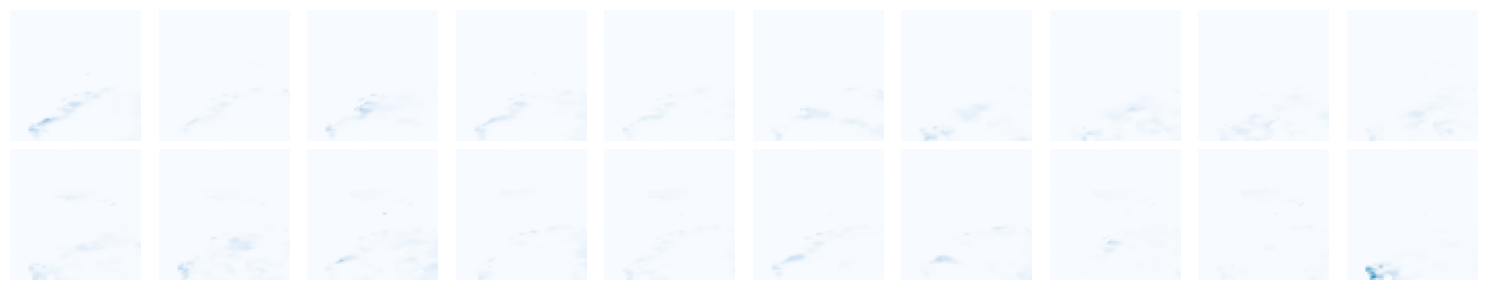

In [14]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for t in range(10):
    axes[0, t].imshow(X[0, t, 0], cmap="Blues", vmin=0, vmax=1)
    axes[1, t].imshow(y[0, t, 0], cmap="Blues", vmin=0, vmax=1)
    axes[0, t].axis("off")
    axes[1, t].axis("off")
plt.tight_layout()
plt.show()

## 2. ConvLSTM architecture

In [ ]:
# 2.1 convLSTM cell module
class ConvLSTMCell(nn.Module):
    def __init__(self, in_channels, hidden_channels, kernel_size=KERNEL_SIZE):
        super().__init__()
        if kernel_size % 2 != 1:
            raise ValueError("kernel size must be odd")
        self.hidden_channels = hidden_channels
        padding = kernel_size // 2
        self.gate_conv = nn.Conv2d(in_channels + hidden_channels,
                                   4 * hidden_channels,
                                   kernel_size=kernel_size,
                                   padding=padding)
    def forward(self, x, state=None):
        B, _, H, W = x.shape
        if state is None:
            h_prev = x.new_zeros(B, self.hidden_channels, H, W)
            c_prev = x.new_zeros(B, self.hidden_channels, H, W)
        else:
            h_prev, c_prev = state
        combined = torch.cat((x, h_prev), dim=1)
        packed = self.gate_conv(combined)
        i, f, o, g = packed.chunk(4, dim=1)
        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        o = torch.sigmoid(o)
        g = torch.tanh(g)
        c = f * c_prev + i * g
        h = o * torch.tanh(c)
        return h, c
# 2.2 convLSTM encoder-forecaster model
class ConvLSTMEncoder(nn.Module):
    def __init__(self, hidden_channels = HIDDEN_CHANNELS, kernel_size=KERNEL_SIZE):
        super().__init__()
        self.cells = nn.ModuleList([
            ConvLSTMCell(
                in_channels=1,
                hidden_channels=hidden_channels[0],
                kernel_size=kernel_size
            ),
            ConvLSTMCell(
                in_channels=hidden_channels[0],
                hidden_channels=hidden_channels[1],
                kernel_size=kernel_size
            )
        ])
    def forward(self, x):
        states = [None, None]
        for t in range(x.shape[1]):
            xt = x[:, t]
            states[0] = self.cells[0](xt, states[0])
            h1, _ = states[0]
            states[1] = self.cells[1](h1, states[1])
        return states
class ConvLSTMForecaster(nn.Module):
    def __init__(self, hidden_channels=HIDDEN_CHANNELS, kernel_size=KERNEL_SIZE):
        super().__init__()
        self.cells = nn.ModuleList([
            ConvLSTMCell(in_channels=1,
                         hidden_channels=hidden_channels[0],
                         kernel_size=kernel_size),
            ConvLSTMCell(in_channels=hidden_channels[0],
                         hidden_channels=hidden_channels[1],
                         kernel_size=kernel_size)
        ])
        self.output_head = nn.Conv2d(hidden_channels[1], 1, kernel_size=1)
    def forward(self, states, last_observed, targets=None, n_steps=10):
        h1, c1 = states[0]
        h2, c2 = states[1]
        current = last_observed
        predictions = []
        for t in range(n_steps):
            h1, c1 = self.cells[0](
                current, (h1, c1)
            )
            h2, c2 = self.cells[1](
                h1, (h2, c2)
            )
            prediction = torch.sigmoid(self.output_head(h2))
            predictions.append(prediction)
            current = prediction
        return torch.stack(predictions, dim=1)
class ConvLSTMModel(nn.Module):
    def __init__(self, hidden_channels=HIDDEN_CHANNELS, kernel_size=KERNEL_SIZE):
        super().__init__()
        self.encoder = ConvLSTMEncoder(hidden_channels=hidden_channels, kernel_size=kernel_size)
        self.forecaster = ConvLSTMForecaster(hidden_channels=hidden_channels, kernel_size=kernel_size)
    def forward(self, x, targets=None, n_steps=10):
        states = self.encoder(x)
        predictions = self.forecaster(states=states, last_observed=x[:, -1], targets=targets, n_steps=n_steps)
        return predictions

## 3. TrajGRU architecture

In [ ]:
def warp(feature, u, v):
    B, C, H, W = feature.shape
    device, dtype = feature.device, feature.dtype
    y = (torch.arange(H, device=device, dtype=dtype) + 0.5) * (2 / H) - 1
    x = (torch.arange(W, device=device, dtype=dtype) + 0.5) * (2 / W) - 1
    yy, xx = torch.meshgrid(y, x, indexing="ij")
    base = torch.stack((xx, yy), dim=-1)
    flow_norm = torch.stack(
        (u * (2/W), v * (2/H)), dim=-1
    )
    grid = base.unsqueeze(0) + flow_norm
    return F.grid_sample(
        feature, grid, mode="bilinear", padding_mode="zeros", align_corners=False
    )
class FlowSubnetwork(nn.Module):
    def __init__(self, in_channels, hidden_channels, L=NUM_LINKS):
        super().__init__()
        self.L = L
        self.net = nn.Sequential(
            nn.Conv2d(in_channels + hidden_channels,
                      32, kernel_size=5, padding=2),
            nn.LeakyReLU(negative_slope=0.2),
            nn.Conv2d(32, 2*L, kernel_size=5, padding=2)
        )
    def forward(self, x, h):
        flow = self.net(torch.cat((x, h), dim=1))
        B, _, H, W = flow.shape
        flow = flow.reshape(B, self.L, 2, H, W)
        return flow[:, :, 0], flow[:, :, 1]
# 3.1 trajGRU cell module
class TrajGRUCell(nn.Module):
    def __init__(self, in_channels, hidden_channels, kernel_size=KERNEL_SIZE, L=NUM_LINKS):
        super().__init__()
        if kernel_size % 2 != 1:
            raise ValueError("kernel size must be odd")
        self.hidden_channels = hidden_channels
        self.L = L
        padding = kernel_size // 2
        self.flow_net = FlowSubnetwork(in_channels, hidden_channels, L=L)
        self.xgate = nn.Conv2d(in_channels, 3 * hidden_channels, kernel_size=kernel_size, padding=padding)
        self.h_proj = nn.ModuleList([
            nn.Conv2d(hidden_channels, 3 * hidden_channels, kernel_size=1)
            for _ in range(L)
        ])
    def forward(self, x, h=None):
        B, _, H, W = x.shape
        if h is None:
            h = x.new_zeros(B, self.hidden_channels, H, W)
        U, V = self.flow_net(x, h)
        projected = 0
        for l in range(self.L):
            warped = warp(h, U[:, l], V[:, l])
            projected = projected + self.h_proj[l](warped)
        xz, xr, xh = self.xgate(x).chunk(3, dim=1)
        hz, hr, hh = projected.chunk(3, dim=1)
        z = torch.sigmoid(xz + hz)
        r = torch.sigmoid(xr + hr)
        h_tilde = torch.tanh(xh + r * hh)
        return (1 - z) * h_tilde + z * h
# 3.2 trajGRU encoder-forecaster model 
class TrajGRUEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.cells = nn.ModuleList([
            TrajGRUCell(1, 64, L=NUM_LINKS),
            TrajGRUCell(64, 64, L=NUM_LINKS)
        ])
    def forward(self, x):
        h1 = None
        h2 = None
        for t in range(x.shape[1]):
            xt = x[:, t]
            h1 = self.cells[0](xt, h1)
            h2 = self.cells[1](h1, h2)
        return [h1, h2]
class TrajGRUForecaster(nn.Module):
    def __init__(self):
        super().__init__()
        self.cells = nn.ModuleList([
            TrajGRUCell(1, 64, L=NUM_LINKS),
            TrajGRUCell(64, 64, L=NUM_LINKS)
        ])
        self.output_heads = nn.Conv2d(64, 1, kernel_size=1)
    def forward(self, states, n_steps=10):
        h1, h2 = states
        current = h1.new_zeros(h1.shape[0], 1, h1.shape[2], h1.shape[3])
        predictions = []
        for _ in range(n_steps):
            h1 = self.cells[0](current, h1)
            h2 = self.cells[1](h1, h2)
            current = torch.sigmoid(self.output_heads(h2))
            predictions.append(current)
        return torch.stack(predictions, dim=1)
class TrajGRUModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = TrajGRUEncoder()
        self.forecaster = TrajGRUForecaster()
    def forward(self, x, n_steps=10):
        states = self.encoder(x)
        return self.forecaster(states, n_steps)

## 4. Training & evaluation 

In [17]:
from tqdm import tqdm
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    total_samples = 0
    for X, y in tqdm(loader):
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)
        pred = model(X)
        loss = criterion(pred, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=CLIP_MAX_NORM)
        optimizer.step()
        total_loss += loss.item() * X.size(0)
        total_samples += X.size(0)
    return total_loss / total_samples

In [18]:
@torch.no_grad()
def validate_one_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_samples = 0
    for X, y in tqdm(loader):
        X, y = X.to(device), y.to(device)
        pred = model(X)
        loss = criterion(pred, y)
        total_loss += loss.item() * X.size(0)
        total_samples += X.size(0)
    return total_loss / total_samples

### 4.1 unified training loop

In [19]:
def train_model(train_loader, val_loader, model_name="convlstm", num_epochs=2, device=device):
    if model_name == "convlstm":
        model = ConvLSTMModel().to(device)
    else:
        model = TrajGRUModel().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr = LEARNING_RATE)
    criterion = nn.MSELoss()
    train_losses = []
    val_losses = []
    for epoch in range(num_epochs):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
        val_loss = validate_one_epoch(model, val_loader, criterion, device)
        print(f"Epoch: {epoch+1:2d}, train_loss: {train_loss:.4f}, val_loss: {val_loss:.4f}")
        train_losses.append(train_loss)
        val_losses.append(val_loss)
    plt.plot(train_losses, marker='o', label='train_loss')
    plt.plot(val_losses, marker='+', label='val_loss')
    plt.legend()
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.show()
    return model, optimizer

100%|██████████| 27/27 [00:02<00:00, 11.20it/s]


Epoch:  1, train_loss: 0.0073, val_loss: 0.0016


100%|██████████| 27/27 [00:02<00:00, 11.13it/s]


Epoch:  2, train_loss: 0.0018, val_loss: 0.0016


100%|██████████| 27/27 [00:02<00:00, 11.13it/s]


...

Epoch:  8, train_loss: 0.0018, val_loss: 0.0016


100%|██████████| 27/27 [00:02<00:00, 11.10it/s]


Epoch:  9, train_loss: 0.0018, val_loss: 0.0016


100%|██████████| 27/27 [00:02<00:00, 11.09it/s]

Epoch: 10, train_loss: 0.0018, val_loss: 0.0016


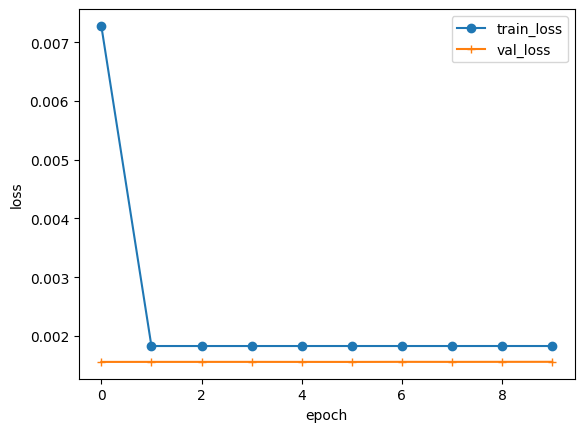

In [20]:
convlstm, _ = train_model(train_loader, val_loader, model_name="convlstm", num_epochs=10, device=device)

100%|██████████| 27/27 [00:11<00:00,  2.39it/s]


Epoch:  1, train_loss: 0.0035, val_loss: 0.0016


100%|██████████| 27/27 [00:11<00:00,  2.39it/s]

Epoch:  2, train_loss: 0.0018, val_loss: 0.0016


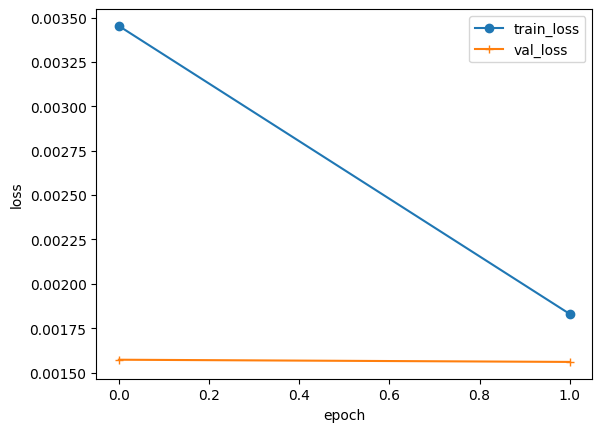

In [21]:
trajgru, _ = train_model(train_loader, val_loader, model_name="trajgru", num_epochs=2, device=device)

### 4.2 evaluation & visualizations

In [22]:
@torch.no_grad()
def per_frame_mse(model, loader, device):
    model.eval()
    error_sum = None
    count = 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        pred = model(X)
        err = (pred - y).square().sum(dim=(0, 2, 3, 4))
        if error_sum is None:
            error_sum = torch.zeros_like(err)
        error_sum += err
        count += X.shape[0] * y.shape[2] * y.shape[3] * y.shape[4]
    return (error_sum / count).cpu()

In [23]:
mse_c = per_frame_mse(convlstm, test_loader, device)
mse_t = per_frame_mse(trajgru, test_loader, device)
print(mse_c, mse_t)

tensor([0.0016, 0.0016, 0.0015, 0.0012, 0.0015, 0.0016, 0.0017, 0.0015, 0.0013,
        0.0015]) tensor([0.0016, 0.0016, 0.0015, 0.0012, 0.0015, 0.0016, 0.0017, 0.0015, 0.0014,
        0.0015])


In [24]:
torch.save(convlstm.state_dict(), "convlstm.pt")
torch.save(trajgru.state_dict(), "trajgru.pt")
print("checkpoints saved")

checkpoints saved


In [33]:
@torch.no_grad()
def show_forecast_comparison(model_conv, model_traj, loader, device, sample_idx):
    model_conv.eval()
    model_traj.eval()
    X, y = next(iter(loader))
    X, y = X.to(device), y.to(device)
    pred_c = model_conv(X)
    pred_t = model_traj(X)
    frames = [0, 4, 9]
    names = ["Ground truth", "ConvLSTM", "TrajGRU"]
    fig, axes = plt.subplots(3, 3, figsize=(7, 7))
    for row, (name, seq) in enumerate([
        (names[0], y),
        (names[1], pred_c),
        (names[2], pred_t)
    ]):
        for col, t in enumerate(frames):
            axes[row, col].imshow(
                seq[sample_idx, t, 0].cpu(),
                cmap="Blues",
                vmin=0, vmax=1
            )
            # axes[row, col].axis("off")
            if row == 0:
                axes[row, col].set_title(f"Frame {t+1}")
            if col == 0:
                axes[row, col].set_ylabel(name)
    plt.tight_layout()
    plt.show()

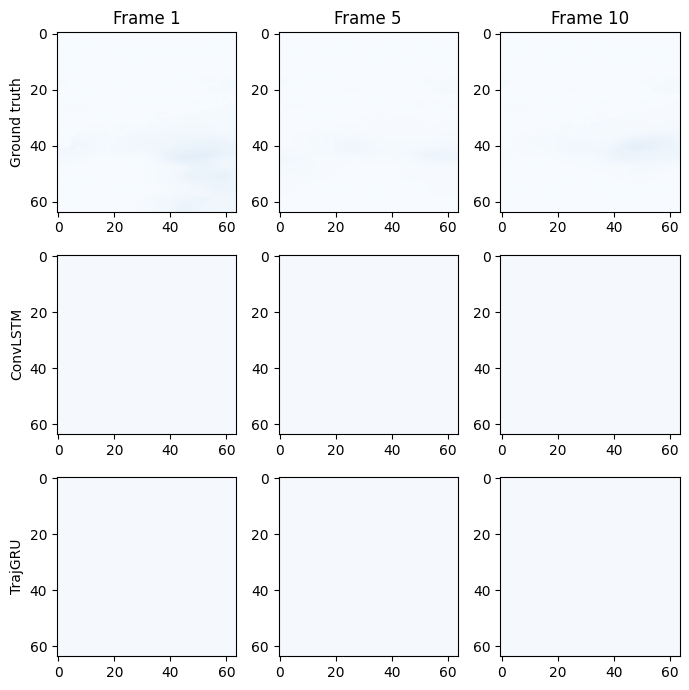

In [34]:
show_forecast_comparison(convlstm, trajgru, test_loader, device, 0)